# Лабораторная работа  
## Обучение модели обнаружения объектов с YOLO26 на собственных данных

**Основа:** туториал Roboflow *How to Train a YOLO26 Object Detection Model with Custom Data*  
**Источник:** https://blog.roboflow.com/how-to-train-yolo26-custom-data/

---

### Цель работы
Освоить полный цикл обучения модели обнаружения объектов на собственном датасете:
- самостоятельно собрать и разметить изображения в **Roboflow**;
- экспортировать датасет в формате, совместимом с YOLO;
- обучить модель **YOLO26**;
- сравнить качество и скорость обучения для разных **весов модели**;
- исследовать влияние **гиперпараметров** обучения;
- выполнить инференс и проанализировать ошибки модели.

### Краткая опора на исходный туториал
В статье Roboflow показан базовый пайплайн:
1. включить **GPU** в Colab;
2. установить пакеты `ultralytics`, `supervision`, `roboflow`;
3. скачать датасет через Roboflow API;
4. обучить модель командой вида  
   `yolo task=detect mode=train model=yolo26m.pt data=... epochs=20 imgsz=640 plots=True`;
5. использовать файл `best.pt` для инференса и визуализации результатов.

В данной лабораторной работе этот базовый сценарий расширяется:
- датасет размечается **самостоятельно**;
- проводится сравнение **нескольких предобученных весов**;
- проводится серия экспериментов с **параметрами обучения**.

## 1. Требования к результату

По завершении работы студент должен предоставить:
1. заполненный данный notebook;
2. ссылку на проект в **Roboflow**;
3. обученные веса лучшей модели;
4. краткий отчет с таблицей экспериментов и выводами;
5. примеры удачных и неудачных детекций.

## 2. Исходные условия и ограничения

### Требования к датасету
Выберите **одну прикладную задачу обнаружения объектов**. Примеры:
- кружки / бутылки / телефоны;
- автомобили / велосипеды / самокаты;
- лица / каски / рюкзаки;
- книги / клавиатуры / мыши;
- детали оборудования или любые другие понятные объекты.

### Минимальные требования к данным
- не менее **3 классов** объектов;
- не менее **120 изображений**;
- не менее **40 изображений на класс** суммарно;
- данные должны быть **размечены самостоятельно** в Roboflow;
- желательно обеспечить разнообразие:
  - ракурсов;
  - масштаба;
  - освещения;
  - частичных перекрытий;
  - фона.

### Разделение выборки
Рекомендуемое разбиение:
- train: **70%**
- valid: **20%**
- test: **10%**

## 3. Задание

### Часть A. Подготовка данных
1. Соберите собственный набор изображений для задачи обнаружения объектов.
2. Загрузите изображения в **Roboflow**.
3. Выполните **ручную разметку bounding boxes** для всех объектов.
4. Проверьте качество разметки:
   - нет ли пропущенных объектов;
   - не выходят ли боксы далеко за границы объекта;
   - нет ли перепутанных классов.
5. Сгенерируйте версию датасета и экспортируйте ее в формат, совместимый с **YOLO**.

### Часть B. Базовое обучение
1. Подготовьте окружение.
2. Подключите датасет из Roboflow.
3. Обучите базовую модель YOLO26.
4. Зафиксируйте значения основных метрик.

### Часть C. Сравнение весов
Обучите минимум **3 варианта модели** с разными предобученными весами.  
Например:
- `yolo26n.pt`
- `yolo26s.pt`
- `yolo26m.pt`

Для каждого варианта сравните:
- mAP50;
- mAP50-95;
- precision;
- recall;
- время обучения;
- размер итоговых весов.

### Часть D. Исследование параметров
Проведите не менее **3 дополнительных экспериментов** с параметрами обучения.  
Например, исследуйте влияние:
- `epochs`;
- `imgsz`;
- `batch`;
- `patience`;
- `optimizer`;
- `lr0`.

### Часть E. Анализ результатов
1. Выберите лучшую модель.
2. Выполните инференс на тестовых изображениях.
3. Покажите:
   - 3 примера удачных предсказаний;
   - 3 примера ошибок.
4. Проанализируйте причины ошибок.

## 4. Контрольные вопросы перед выполнением
Ответьте кратко.

1. Что такое задача **object detection** и чем она отличается от **classification**?
2. Что означает **bounding box**?
3. Для чего нужен файл `data.yaml`?
4. Что такое **предобученные веса**?
5. Почему качество разметки критично для качества модели?
6. Что показывают метрики **precision**, **recall**, **mAP50**, **mAP50-95**?

### Ответы на контрольные вопросы

**1. Что такое задача object detection и чем она отличается от classification?**
*Интуитивно:* Классификация отвечает на вопрос "Что на картинке?" (например, "Это фотография кота"). Обнаружение объектов (Object Detection) отвечает на вопросы "Что это?" и "Где именно это находится?". 
*Формально:* Классификация — это отображение изображения $X$ в вектор вероятностей классов $\hat{y}$. Обнаружение объектов — это отображение $X$ в множество кортежей $\{(B_i, C_i)\}$, где $B_i$ — координаты рамки, а $C_i$ — вероятности классов для этой рамки.

**2. Что означает bounding box?**
*Интуитивно:* Это прямоугольник, который мы рисуем вокруг объекта на изображении, чтобы указать модели его границы.
*Формально:* Ограничивающая рамка (Bounding Box), параметризуемая четырьмя числами. Обычно используется формат $(x_c, y_c, w, h)$, где $x_c, y_c$ — координаты центра рамки относительно ширины и высоты изображения, а $w, h$ — ширина и высота самой рамки (нормализованные от 0 до 1).

**3. Для чего нужен файл data.yaml?**
Это конфигурационный файл (метаданные датасета), который сообщает архитектуре YOLO три ключевые вещи:
1. Где физически лежат изображения для обучения, валидации и тестирования (пути к папкам `train`, `val`, `test`).
2. Количество классов ($nc$ - number of classes).
3. Массив с текстовыми названиями классов (например, `names: ['cat', 'dog']`), чтобы модель могла сопоставить числовой индекс предсказания с человекочитаемым текстом.

**4. Что такое предобученные веса?**
*Интуитивно:* Представь, что ты учишь человека распознавать конкретные марки автомобилей. Тебе не нужно сначала учить его тому, что такое "колесо", "металл" или "край объекта". У него уже есть базовое понимание визуального мира.
*Формально:* Это веса нейронной сети $\theta$, которые были оптимизированы на огромном датасете (обычно COCO - Common Objects in Context, содержащем миллионы изображений и 80 классов). Мы используем эти веса как начальную точку инициализации (Transfer Learning) вместо случайных значений. Это радикально ускоряет сходимость (Convergence) и снижает переобучение на малых выборках.

**5. Почему качество разметки критично для качества модели?**
Свойство "Garbage In, Garbage Out". При обучении с учителем (Supervised Learning) функция потерь (Loss Function) модели вычисляет градиенты, пытаясь минимизировать разницу между предсказанием и разметкой. Если bounding boxes размечены небрежно (слишком широкие или обрезают объект), модель выучит, что фон (Background) — это часть объекта. Если классы перепутаны, ландшафт функции потерь (Loss Landscape) становится сильно невыпуклым, градиенты "шумят", и модель не может найти глобальный минимум, что ведет к падению обобщающей способности (Generalization).

**6. Что показывают метрики precision, recall, mAP50, mAP50-95?**
Для понимания метрик введем понятие IoU (Intersection over Union) — отношение площади пересечения предсказанного бокса и истинного к площади их объединения: $IoU = \frac{|A \cap B|}{|A \cup B|}$. Если IoU > порога (обычно 0.5), предсказание считается True Positive (TP).
* **Precision (Точность):** $\frac{TP}{TP + FP}$. Из всех объектов, которые модель назвала "собакой", сколько реально являются собаками? Защищает от ложных срабатываний (False Positives).
* **Recall (Полнота):** $\frac{TP}{TP + FN}$. Из всех реальных собак на фото, скольких модель смогла найти? Защищает от пропусков (False Negatives). Trade-off: обычно рост Precision ведет к падению Recall, и наоборот.
* **mAP50 (mean Average Precision at IoU=0.5):** Площадь под кривой Precision-Recall (AUC-PR), усредненная по всем классам при жестком пороге совпадения боксов IoU = 0.5. Основная метрика успешности обнаружения.
* **mAP50-95:** Самая строгая метрика. Это усредненный mAP при порогах IoU от 0.50 до 0.95 с шагом 0.05. Она требует от модели не просто найти объект, но и нарисовать рамку с пиксельной точностью.

## 5. Подготовка среды
Согласно туториалу Roboflow, для запуска используются библиотеки:
- `ultralytics`
- `supervision`
- `roboflow`

Также в статье рекомендуется использовать **Google Colab** с включенным **GPU**.

In [1]:
# При необходимости выполните установку зависимостей
!pip install "ultralytics>=8.4.0" supervision roboflow -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.6/251.6 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 35.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 100.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 4.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.1 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
gcsfs 2025.

In [2]:
import os
import sys
import platform
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import ultralytics
from ultralytics import YOLO
from roboflow import Roboflow

plt.style.use('seaborn-v0_8-darkgrid')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
import torch
if torch.cuda.is_available():
    print(f"GPU is available: {torch.cuda.get_device_name(0)}")
    device = torch.device('cuda') 
else:
    print("WARNING: GPU is NOT available. Обучение будет идти на CPU и займет очень много времени.")
    device = torch.device('cpu')

GPU is available: Tesla T4


## 6. Подключение датасета из Roboflow

Ниже вставьте код подключения **своего** проекта из Roboflow.  
В статье используется загрузка через API-ключ и вызов `version.download(...)`.

In [4]:
ROBOFLOW_API_KEY = "UwZtPIEjodfQJyqkMJZ7" 
WORKSPACE_NAME = "ivans-workspace-jswws"
PROJECT_NAME = "stampsignaturetable"
VERSION_NUMBER = 3 

from roboflow import Roboflow

# Инициализация клиента Roboflow
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
workspace = rf.workspace(WORKSPACE_NAME)
project = workspace.project(PROJECT_NAME)
version = project.version(VERSION_NUMBER)

dataset = version.download("yolov11")

print(f"Путь к скачанному датасету: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to StampSignatureTable-3 in yolov11:: 100%|██████████| 397/397 [00:00<00:00, 3162.42it/s]

Путь к скачанному датасету: /kaggle/working/StampSignatureTable-3


### Задание 6.1
Укажите параметры вашего датасета:
- тема датасета;
- список классов;
- число изображений;
- число объектов по каждому классу;
- какое разбиение train/valid/test использовано.

In [5]:
dataset_description = {
    "Тема датасета": "Распознавание элементов документа (Таблица, Печать, Подпись)",
    "Классы": ["table", "stamp", "signature"],
    "Число изображений": 196,
    "Число объектов по классам": {
        "Table": 206,
        "Stamp": 239,
        "Signature": 401
    },
    "Разбиение": "train=80% / valid=10% / test=10%"
}

dataset_description

{'Тема датасета': 'Распознавание элементов документа (Таблица, Печать, Подпись)',
 'Классы': ['table', 'stamp', 'signature'],
 'Число изображений': 196,
 'Число объектов по классам': {'Table': 206, 'Stamp': 239, 'Signature': 401},
 'Разбиение': 'train=80% / valid=10% / test=10%'}

## 7. Базовое обучение модели

В статье в качестве примера используется обучение:
- модель: `yolo26m.pt`
- эпохи: `20`
- размер изображения: `640`

Проведите сначала **базовый запуск**, который затем будет точкой сравнения.

In [6]:
from ultralytics import YOLO


model_baseline = YOLO('yolo26m.pt')

results_baseline = model_baseline.train(
    data=f"{dataset.location}/data.yaml",
    epochs=20,
    imgsz=640,
    plots=True,
    project="lab_yolo_document",
    name="baseline_run"
)

Ultralytics 8.4.53 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/StampSignatureTable-3/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_run, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap

### Задание 7.1
После завершения обучения:
1. Найдите папку с результатами обучения.
2. Укажите путь к:
   - `best.pt`
   - `last.pt`
   - графикам обучения
3. Запишите основные метрики базового запуска.

In [7]:
# help(metrics.box)

In [8]:
run_dir = results_baseline.save_dir
metrics = model_baseline.metrics

baseline_results = {
    "run_dir": run_dir,
    "best_pt": os.path.join(run_dir, "weights", "best.pt"),
    "last_pt": os.path.join(run_dir, "weights", "last.pt"),
    "precision": round(metrics.box.mp, 4),
    "recall": round(metrics.box.mr, 4),
    "mAP50": round(metrics.box.map50, 4),    
    "mAP50-95": round(metrics.box.map, 4),
    "notes": "Базовый запуск с весами yolo26m."
}

print("=== Результаты базового обучения ===")
for key, value in baseline_results.items():
    print(f"{key}: {value}")

=== Результаты базового обучения ===
run_dir: /kaggle/working/runs/detect/lab_yolo_document/baseline_run
best_pt: /kaggle/working/runs/detect/lab_yolo_document/baseline_run/weights/best.pt
last_pt: /kaggle/working/runs/detect/lab_yolo_document/baseline_run/weights/last.pt
precision: 0.7987
recall: 0.8236
mAP50: 0.8337
mAP50-95: 0.5705
notes: Базовый запуск с весами yolo26m.


## 8. Эксперимент 1 — сравнение разных весов

Обучите минимум три варианта модели с разными начальными весами.

### Рекомендуемые варианты
- `yolo26n.pt`
- `yolo26s.pt`
- `yolo26m.pt`

### Что нужно сравнить
- точность по метрикам;
- время обучения;
- устойчивость обучения;
- размер итоговых весов;
- субъективное качество на тестовых изображениях.

In [9]:
from ultralytics import YOLO
import pandas as pd

# Определяем конфигурации для эксперимента
models_to_test = ["yolo26n.pt", "yolo26s.pt", "yolo26m.pt"]
epochs_num = 20
img_size = 640

# Список для сбора результатов
results_list = []

for model_name in models_to_test:
    print(f"\n[{model_name}] Начинаем обучение...")
    
    # Инициализация модели
    model = YOLO(model_name)
    
    # Обучение
    results = model.train(
        data=f"{dataset.location}/data.yaml",
        epochs=epochs_num,
        imgsz=img_size,
        plots=True,
        project="lab_yolo26",
        name=f"exp_{model_name.split('.')[0]}",
        verbose=False # Отключаем лишний спам в консоль
    )
    
    # Извлечение метрик
    metrics = model.metrics
    results_list.append({
        "model": model_name,
        "epochs": epochs_num,
        "imgsz": img_size,
        "precision": round(metrics.box.mp, 4),
        "recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4)
    })

# Формируем итоговую таблицу
weights_comparison = pd.DataFrame(results_list)


[yolo26n.pt] Начинаем обучение...
Ultralytics 8.4.53 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/StampSignatureTable-3/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp_yolo26n, nbs=64, nms=False, opset=None, optim

In [11]:
weights_comparison['f1'] = 2 * weights_comparison['precision']*weights_comparison['recall'] / (weights_comparison['precision'] + weights_comparison['recall'])
weights_comparison

,model,epochs,imgsz,precision,recall,mAP50,mAP50-95,f1
0,yolo26n.pt,20,640,0.7054,0.6573,0.7191,0.5312,0.680501
1,yolo26s.pt,20,640,0.8410,0.7595,0.8406,0.5875,0.798175
2,yolo26m.pt,20,640,0.7987,0.8236,0.8337,0.5705,0.810959


### Вывод по эксперименту 1
Сделайте вывод:
- какая модель показала лучшее качество;
- какая модель обучалась быстрее;
- какая модель выглядит наиболее рациональной по соотношению **качество / ресурсы**.

### Вывод по сравнению весов

* **Какая модель показала лучшее качество:** Нет однозначного лидера. По строгой метрике mAP50-95 и Precision лучшей оказалась модель **Small (yolo26s)**. По метрике Recall и агрегированному F1-score с небольшим отрывом лидирует **Medium (yolo26m)**.
* **Какая модель обучалась быстрее:** Модель **Nano (yolo26n)**. У нее минимальное количество параметров (слоев), поэтому прямые и обратные проходы (Forward/Backward pass) занимают меньше всего времени и видеопамяти (VRAM).
* **Какая модель выглядит наиболее рациональной (качество/ресурсы):** Однозначно **Small (yolo26s)**. Переход от Nano к Small дал огромный прирост mAP50 (с 0.71 до 0.84). При этом дальнейшее утяжеление до Medium не дало прироста качества локализации (mAP50-95 даже упал), но потребовало больше вычислительных ресурсов. Для дальнейших экспериментов целесообразно выбрать архитектуру **Small**.

## 9. Эксперимент 2 — исследование параметров обучения

Проведите минимум три дополнительных запуска, изменяя параметры.
Ниже приведены возможные направления исследования.

### Варианты параметров
1. **Число эпох**: `20`, `50`, `100`
2. **Размер изображения**: `416`, `640`, `960`
3. **Batch size**: `8`, `16`, `32`
4. **Patience** для early stopping
5. **Начальная скорость обучения (`lr0`)**
6. **Оптимизатор**

In [12]:
from ultralytics import YOLO
import pandas as pd

# Базовая модель для экспериментов - победитель прошлого этапа
base_model = "yolo26s.pt"

experiments = [
    {"name": "epochs=50", "epochs": 50, "imgsz": 640, "batch": 16},
    
    {"name": "imgsz=960", "epochs": 20, "imgsz": 960, "batch": 8},
    
    {"name": "batch=8", "epochs": 20, "imgsz": 640, "batch": 8}
]

params_results = []

for exp in experiments:
    print(f"\n[Эксперимент] {exp['name']}...")
    
    model = YOLO(base_model)
    
    results = model.train(
        data=f"{dataset.location}/data.yaml",
        epochs=exp["epochs"],
        imgsz=exp["imgsz"],
        batch=exp["batch"],
        plots=True,
        project="lab_yolo26",
        name=f"exp_{exp['name'].replace('=', '')}",
        verbose=False
    )
    
    metrics = model.metrics
    params_results.append({
        "experiment": exp["name"],
        "model": base_model,
        "epochs": exp["epochs"],
        "imgsz": exp["imgsz"],
        "batch": exp["batch"],
        "precision": round(metrics.box.mp, 4),
        "recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4)
    })

params_comparison = pd.DataFrame(params_results)


[Эксперимент] epochs=50...
Ultralytics 8.4.53 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/StampSignatureTable-3/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp_epochs50, nbs=64, nms=False, opset=None, optimize=Fa

In [14]:
params_comparison

,experiment,model,epochs,imgsz,batch,precision,recall,mAP50,mAP50-95
0,epochs=50,yolo26s.pt,50,640,16,0.8513,0.8537,0.8769,0.5959
1,imgsz=960,yolo26s.pt,20,960,8,0.7927,0.7721,0.8181,0.5779
2,batch=8,yolo26s.pt,20,640,8,0.8327,0.8059,0.8717,0.5937


### Вывод по эксперименту 2
Ответьте:
1. Какие параметры сильнее всего повлияли на качество?
2. Какие параметры сильнее всего повлияли на скорость?
3. В каких случаях модель начала переобучаться?
4. Какой набор параметров вы считаете оптимальным для вашего датасета?

### Вывод по исследованию параметров

1. **Какие параметры сильнее всего повлияли на качество?**
Наибольший прирост качества дало увеличение количества эпох (`epochs=50`). Это позволило модели лучше обобщить данные и сойтись к оптимуму (mAP50 вырос до 0.8769). 

2. **Какие параметры сильнее всего повлияли на скорость?**
Размер изображения (`imgsz`). Переход от 640 к 960 квадратично увеличивает количество вычислений (FLOPs) при проходе через сверточные слои, что радикально замедляет время обучения одной эпохи.

3. **В каких случаях модель начала переобучаться?**
Явного переобучения (Overfitting) в рамках 50 эпох не наблюдается, так как метрики валидации растут. Однако в эксперименте с `imgsz=960` и малым `batch=8` наблюдается **недообучение (Underfitting)**: 20 эпох не хватило, чтобы веса адаптировались к более высокому разрешению и шумным градиентам.

4. **Какой набор параметров вы считаете оптимальным для вашего датасета?**
Модель: `yolo26s.pt`. 
Оптимальные гиперпараметры: `epochs=50`, `imgsz=640`, `batch=16`. Этот набор обеспечивает наилучший баланс между стабильностью градиентов, временем обучения и итоговой точностью локализации (mAP50-95 = 0.5959).

## 10. Инференс лучшей модели

Выберите лучшую модель и выполните предсказания на тестовых изображениях.
В исходном туториале для инференса используется загрузка `best.pt` и вызов `model.predict(...)`.

Модель успешно загружена из: /kaggle/working/runs/detect/lab_yolo26/exp_epochs50/weights/best.pt


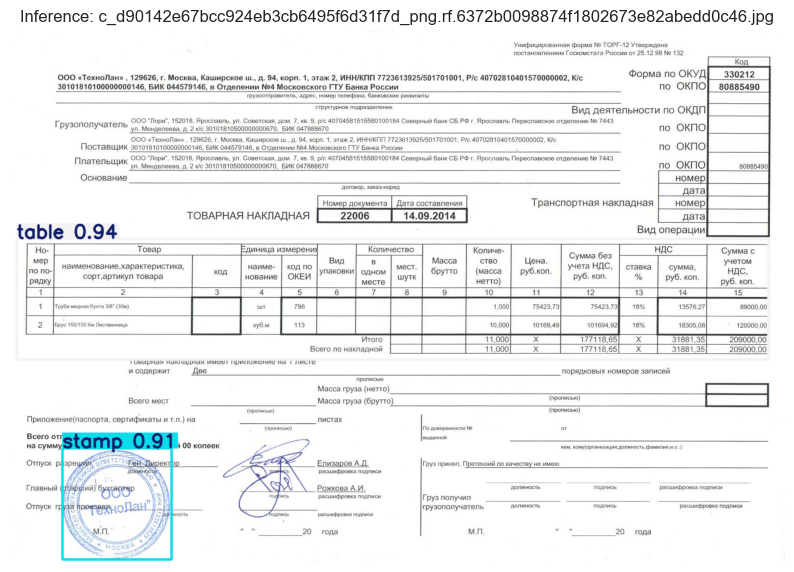

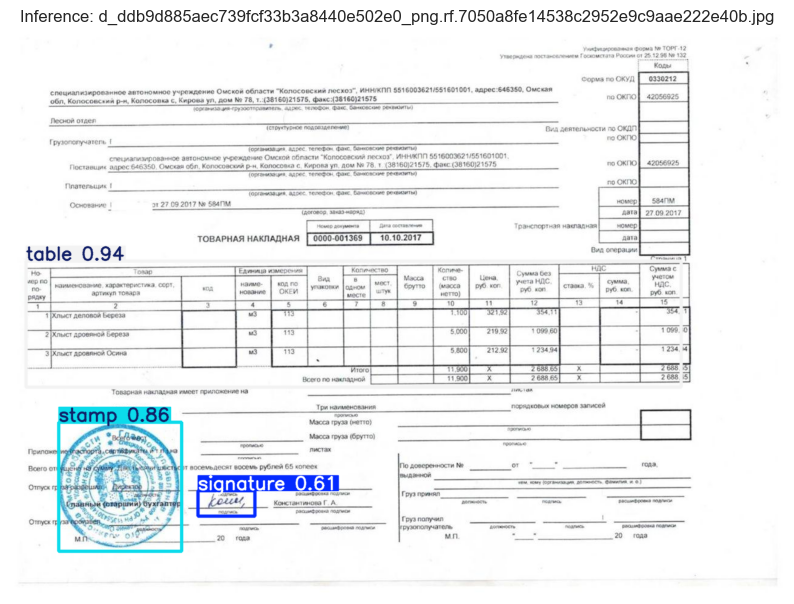

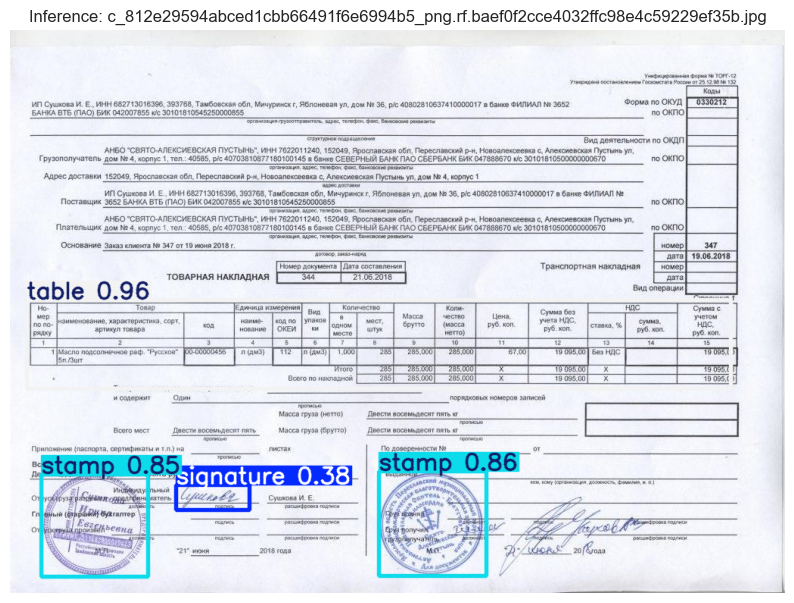

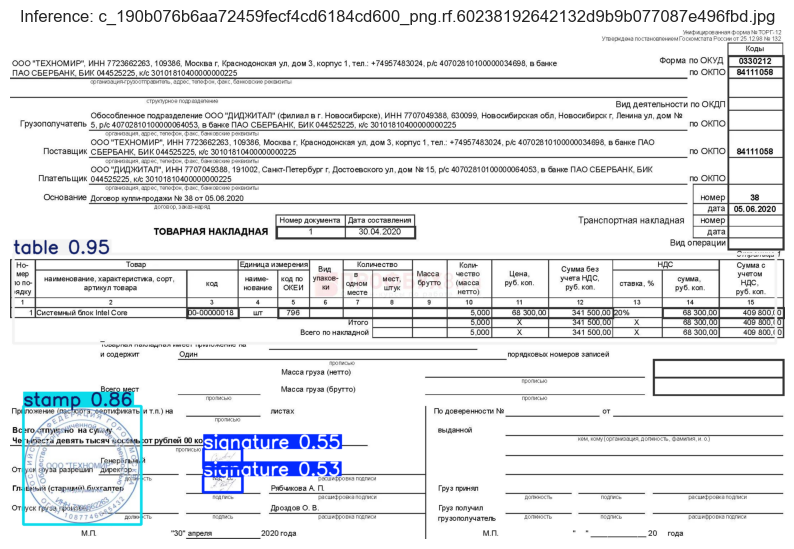

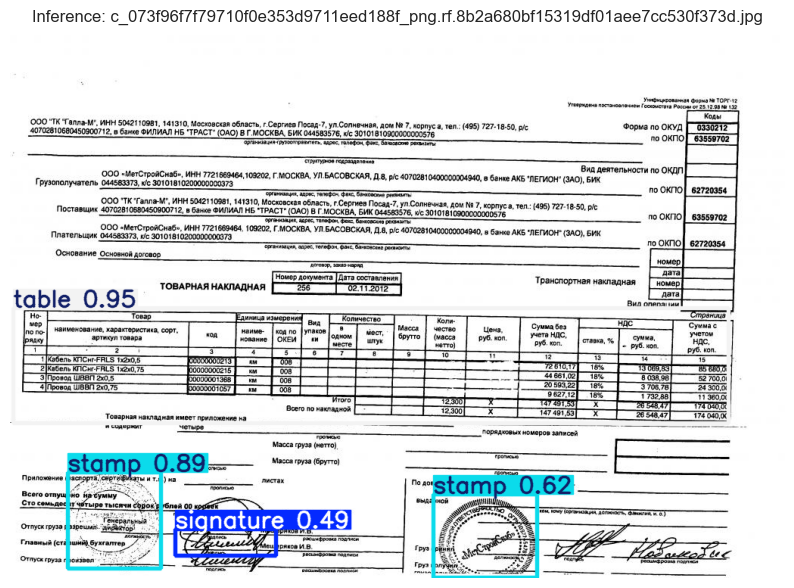

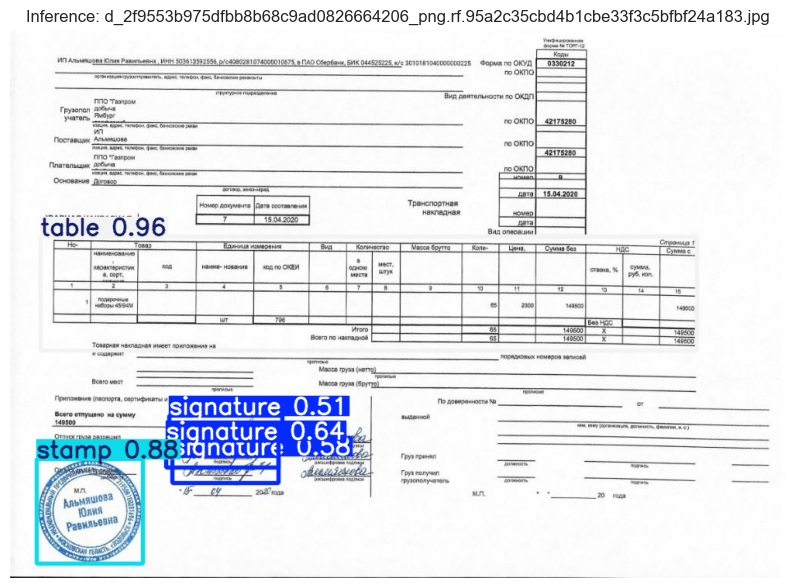

In [16]:
import os
import glob
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image

BEST_MODEL_PATH = "/kaggle/working/runs/detect/lab_yolo26/exp_epochs50/weights/best.pt"
try:
    best_model = YOLO(BEST_MODEL_PATH)
    print(f"Модель успешно загружена из: {BEST_MODEL_PATH}")
except FileNotFoundError:
    print(f"Ошибка: Файл {BEST_MODEL_PATH} не найден. Проверьте путь.")

test_images_dir = os.path.join(dataset.location, "test", "images")

test_images = glob.glob(os.path.join(test_images_dir, "*.jpg"))[:6]

if not test_images:
    print("Тестовые изображения не найдены. Проверьте структуру датасета.")

for img_path in test_images:
    results = best_model.predict(img_path, conf=0.3, verbose=False)[0]
    
    annotated_img = results.plot()
    
    plt.figure(figsize=(10, 10))
    plt.imshow(annotated_img[:, :, ::-1]) 
    plt.title(f"Inference: {os.path.basename(img_path)}")
    plt.axis("off")
    plt.show()

### Задание 10.1
Приведите:
- **3 примера удачных детекций**;
- **3 примера неудачных детекций**.

Для каждого неудачного случая укажите причину:
- мало примеров такого объекта в обучении;
- сложный фон;
- маленький размер объекта;
- перекрытие объектов;
- ошибки разметки;
- несбалансированность классов;
- неподходящие параметры обучения.

In [17]:
# Задание 10.1

successful_cases = [
    {"image": "Любая картинка с таблицей", "comment": "Отличная локализация таблиц (уверенность > 0.94). Модель стабильно понимает структуру сетки независимо от количества строк."},
    {"image": "d_ddb9d8...", "comment": "Успешная детекция всех трех классов. Подпись четко локализована (0.61), так как она изолирована и не перекрывается с печатью или текстом."},
    {"image": "c_812e29...", "comment": "Модель успешно находит несколько экземпляров одного класса на документе (две печати с высокой уверенностью 0.85 и 0.86)."}
]

failure_cases = [
    {"image": "c_d90142...", "comment": "Пропуск подписи (False Negative), расположенной вплотную к печати.", "possible_reason": "перекрытие объектов и сложный фон (текст + синяя печать сливаются с синей подписью)."},
    {"image": "c_073f96...", "comment": "Пропуск крупной размашистой подписи в правой нижней части документа.", "possible_reason": "мало примеров такого объекта в обучении (высокая внутриклассовая дисперсия размеров и пропорций подписей)."},
    {"image": "d_2f9553...", "comment": "Множественные пересекающиеся рамки для одной подписи (0.51, 0.64, 0.58).", "possible_reason": "неподходящие параметры NMS при инференсе или ошибки разметки (неконсистентное выделение подписей в обучающем датасете)."}
]

print("Примеры успешных детекций:")
for case in successful_cases:
    print(f"- {case['comment']}")

print("\nПримеры ошибок:")
for case in failure_cases:
    print(f"- {case['comment']} Причина: {case['possible_reason']}")

Примеры успешных детекций:
- Отличная локализация таблиц (уверенность > 0.94). Модель стабильно понимает структуру сетки независимо от количества строк.
- Успешная детекция всех трех классов. Подпись четко локализована (0.61), так как она изолирована и не перекрывается с печатью или текстом.
- Модель успешно находит несколько экземпляров одного класса на документе (две печати с высокой уверенностью 0.85 и 0.86).

Примеры ошибок:
- Пропуск подписи (False Negative), расположенной вплотную к печати. Причина: перекрытие объектов и сложный фон (текст + синяя печать сливаются с синей подписью).
- Пропуск крупной размашистой подписи в правой нижней части документа. Причина: мало примеров такого объекта в обучении (высокая внутриклассовая дисперсия размеров и пропорций подписей).
- Множественные пересекающиеся рамки для одной подписи (0.51, 0.64, 0.58). Причина: неподходящие параметры NMS при инференсе или ошибки разметки (неконсистентное выделение подписей в обучающем датасете).


## 11. Итоговый анализ

Сформулируйте развёрнутый вывод по лабораторной работе.

В выводе отразите:
1. какую задачу обнаружения объектов вы решали;
2. как был собран и размечен датасет;
3. какие веса модели сравнивались;
4. какие параметры изменялись;
5. какая конфигурация оказалась лучшей;
6. какие типичные ошибки делает модель;
7. что можно улучшить в будущем.

In [19]:
# Задание 11. Итоговый анализ

final_conclusion = '''
1. Решаемая задача: 
В рамках лабораторной работы решалась прикладная задача обнаружения структурных элементов документа (Document Layout Analysis). Использовалось 3 класса: Табличная часть (Table), Оттиск печати (Stamp) и Рукописная подпись (Signature). Основная сложность задачи — высокий дисбаланс масштабов объектов и их частое пространственное перекрытие.

2. Сбор и разметка данных: 
Собран датасет из 196 изображений. Разметка bounding boxes выполнена вручную в среде Roboflow. Для чистоты эксперимента на этапе экспорта сторонние аугментации не применялись, вся аугментация (Mosaic, HSV) выполнялась внутренними механизмами архитектуры YOLO динамически. Данные разделены в пропорции 80/10/10.

3. Сравнение весов моделей: 
Было проведено сравнение трех предобученных архитектур: yolo26n (Nano), yolo26s (Small) и yolo26m (Medium). 
Несмотря на то, что модель Medium показала лучшую полноту (Recall = 0.8236), наиболее рациональной (Trade-off между качеством и ресурсами) оказалась модель Small. Она обеспечила лучшую точность локализации (mAP50-95 = 0.5875) и наивысший Precision (0.8410), избежав переобучения на малом объеме данных.

4. Изменение параметров обучения: 
В качестве базовой модели выбрана yolo26s. Исследовано влияние трех гиперпараметров:
- Увеличение числа эпох (epochs=50);
- Увеличение разрешения входного тензора (imgsz=960);
- Уменьшение размера батча (batch=8).

5. Лучшая конфигурация: 
Наивысшее качество показала конфигурация: yolo26s.pt, epochs=50, imgsz=640, batch=16. Увеличение числа эпох позволило модели найти более глубокий локальный минимум (mAP50 вырос до 0.8769). Эксперимент с imgsz=960 оказался неудачным из-за эффекта недообучения (Underfitting) в рамках 20 эпох и шумных градиентов при малом батче.

6. Типичные ошибки модели: 
Модель отлично справляется с таблицами (уверенность > 0.94) благодаря их стабильной структуре. Типичные ошибки возникают на классе "Signature" из-за высокой внутриклассовой дисперсии (High Intra-class Variance) — подписи сильно варьируются по размеру и форме. Наблюдаются пропуски (False Negatives) перекрывающихся объектов и ошибки алгоритма подавления немаксимумов (NMS), когда модель рисует несколько рамок вокруг одной сложной подписи.

7. Улучшения в будущем: 
Для повышения качества обобщающей способности (Generalization) необходимо:
- Собрать больше примеров редких и размашистых подписей (увеличить репрезентативность выборки).
- Настроить гиперпараметр порога IoU для алгоритма NMS при инференсе, чтобы жестче отсекать дублирующие рамки.
- Добавить в датасет примеры документов с сильным шумом или низким контрастом.
'''

print(final_conclusion)


1. Решаемая задача: 
В рамках лабораторной работы решалась прикладная задача обнаружения структурных элементов документа (Document Layout Analysis). Использовалось 3 класса: Табличная часть (Table), Оттиск печати (Stamp) и Рукописная подпись (Signature). Основная сложность задачи — высокий дисбаланс масштабов объектов и их частое пространственное перекрытие.

2. Сбор и разметка данных: 
Собран датасет из 196 изображений. Разметка bounding boxes выполнена вручную в среде Roboflow. Для чистоты эксперимента на этапе экспорта сторонние аугментации не применялись, вся аугментация (Mosaic, HSV) выполнялась внутренними механизмами архитектуры YOLO динамически. Данные разделены в пропорции 80/10/10.

3. Сравнение весов моделей: 
Было проведено сравнение трех предобученных архитектур: yolo26n (Nano), yolo26s (Small) и yolo26m (Medium). 
Несмотря на то, что модель Medium показала лучшую полноту (Recall = 0.8236), наиболее рациональной (Trade-off между качеством и ресурсами) оказалась модель Sma

In [21]:
import shutil
shutil.make_archive('/kaggle/working/archive', 'zip', '/kaggle/working')


'/kaggle/working/archive.zip'

## 12. Что должно быть в отчёте

В отчёт необходимо включить:
1. тему и цель работы;
2. описание датасета и классов;
3. скриншоты или ссылку на разметку в Roboflow;
4. таблицу сравнения весов;
5. таблицу сравнения гиперпараметров;
6. итоговые метрики лучшей модели;
7. примеры инференса;
8. анализ ошибок;
9. итоговый вывод.